# EDA — Spotify Tracks Dataset

Análisis exploratorio del dataset `spotify_raw` (registrado en `conf/base/catalog.yml`).

**Objetivo:** entender estructura, calidad de datos, distribuciones y relaciones entre variables antes de construir los pipelines de Kedro.

In [1]:
%load_ext kedro.ipython

The kedro.ipython extension is already loaded. To reload it, use:
  %reload_ext kedro.ipython


## 1. Carga de datos

In [2]:
df = catalog.load("spotify_raw")
df.head()

[10/19/26 23:03:50] INFO     Loading data from spotify_raw (CSVDataset)...                     ]8;id=803419;file://C:\Users\Felipe\Desktop\exp2_kedroml\evaluacion2-machine\.venv\Lib\site-packages\kedro\io\data_catalog.py\data_catalog.py]8;;\:]8;id=803420;file://C:\Users\Felipe\Desktop\exp2_kedroml\evaluacion2-machine\.venv\Lib\site-packages\kedro\io\data_catalog.py#1151\1151]8;;\

,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,...,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic
1,1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,...,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic
2,2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,...,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic
3,3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,...,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic
4,4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,...,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic


In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 90
pd.set_option("display.max_columns", None)

## 2. Estructura del dataset

In [4]:
print(f"Filas: {df.shape[0]:,} | Columnas: {df.shape[1]}")
df.info()

Filas: 114,000 | Columnas: 21
<class 'pandas.DataFrame'>
RangeIndex: 114000 entries, 0 to 113999
Data columns (total 21 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   Unnamed: 0        114000 non-null  int64  
 1   track_id          114000 non-null  str    
 2   artists           113999 non-null  str    
 3   album_name        113999 non-null  str    
 4   track_name        113999 non-null  str    
 5   popularity        114000 non-null  int64  
 6   duration_ms       114000 non-null  int64  
 7   explicit          114000 non-null  bool   
 8   danceability      114000 non-null  float64
 9   energy            114000 non-null  float64
 10  key               114000 non-null  int64  
 11  loudness          114000 non-null  float64
 12  mode              114000 non-null  int64  
 13  speechiness       114000 non-null  float64
 14  acousticness      114000 non-null  float64
 15  instrumentalness  114000 non-null  float64
 16  l

La columna `Unnamed: 0` es un índice que quedó guardado en el CSV; no aporta información y se elimina.

In [5]:
df = df.drop(columns="Unnamed: 0")
df.columns.tolist()


[
    'track_id',
    'artists',
    'album_name',
    'track_name',
    'popularity',
    'duration_ms',
    'explicit',
    'danceability',
    'energy',
    'key',
    'loudness',
    'mode',
    'speechiness',
    'acousticness',
    'instrumentalness',
    'liveness',
    'valence',
    'tempo',
    'time_signature',
    'track_genre'
]

**Descripción de las variables**

| Variable | Descripción |
|---|---|
| `track_id`, `artists`, `album_name`, `track_name` | Identificadores de la canción |
| `popularity` | Popularidad 0–100 calculada por Spotify (posible target de regresión) |
| `duration_ms` | Duración en milisegundos |
| `explicit` | Si la letra es explícita |
| `danceability`, `energy`, `valence` | Bailabilidad, energía y positividad (0–1) |
| `speechiness`, `acousticness`, `instrumentalness`, `liveness` | Presencia de voz hablada, acústica, instrumental y en vivo (0–1) |
| `loudness` | Volumen promedio en dB |
| `tempo` | BPM |
| `key`, `mode`, `time_signature` | Tonalidad (0–11), modo mayor/menor (1/0), compás |
| `track_genre` | Género (posible target de clasificación) |

## 3. Calidad de datos

### 3.1 Valores nulos

In [6]:
nulos = df.isna().sum()
nulos[nulos > 0]


artists       1
album_name    1
track_name    1
dtype: int64

In [7]:
df[df.isna().any(axis=1)]

,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
65900,1kR4gIb7nGxHPI3D2ifs59,NaN,NaN,NaN,0,0,False,0.501,0.583,7,-9.46,0,0.0605,0.69,0.00396,0.0747,0.734,138.391,4,k-pop


Solo **1 fila** tiene nulos (sin artista, álbum ni nombre). Se puede eliminar sin impacto.

### 3.2 Duplicados

In [8]:
print("Filas duplicadas exactas:        ", df.duplicated().sum())
print("track_id repetidos:              ", df["track_id"].duplicated().sum())
print("Duplicados ignorando el género:  ", df.drop(columns="track_genre").duplicated().sum())
print("Canciones en más de un género:   ", (df.groupby("track_id")["track_genre"].nunique() > 1).sum())

Filas duplicadas exactas:         450
track_id repetidos:               24259
Duplicados ignorando el género:   23539


Canciones en más de un género:    16299


In [9]:
ejemplo = df["track_id"].value_counts().index[0]
df[df["track_id"] == ejemplo][["track_id", "track_name", "artists", "popularity", "track_genre"]]

,track_id,track_name,artists,popularity,track_genre
8315,6S3JlDAGk3uu3NtZbPnuhS,Baby Blue - Remastered 2010,Badfinger,67,blues
19759,6S3JlDAGk3uu3NtZbPnuhS,Baby Blue - Remastered 2010,Badfinger,67,country
34728,6S3JlDAGk3uu3NtZbPnuhS,Baby Blue - Remastered 2010,Badfinger,67,folk
62226,6S3JlDAGk3uu3NtZbPnuhS,Baby Blue - Remastered 2010,Badfinger,67,j-pop
63087,6S3JlDAGk3uu3NtZbPnuhS,Baby Blue - Remastered 2010,Badfinger,67,j-rock
82064,6S3JlDAGk3uu3NtZbPnuhS,Baby Blue - Remastered 2010,Badfinger,67,power-pop
84129,6S3JlDAGk3uu3NtZbPnuhS,Baby Blue - Remastered 2010,Badfinger,67,psych-rock
99727,6S3JlDAGk3uu3NtZbPnuhS,Baby Blue - Remastered 2010,Badfinger,67,singer-songwriter
102732,6S3JlDAGk3uu3NtZbPnuhS,Baby Blue - Remastered 2010,Badfinger,67,songwriter


No hay filas idénticas, pero **una misma canción aparece varias veces con distinto género**. Esto es importante:

- Para **regresión de popularidad** conviene dejar una fila por `track_id` (si no, el modelo ve la misma canción en train y test → *data leakage*).
- Para **clasificación de género** la misma canción tiene varias etiquetas, lo que introduce ruido.

### 3.3 Valores imposibles o sospechosos

In [10]:
checks = {
    "duration_ms == 0": (df["duration_ms"] == 0).sum(),
    "tempo == 0": (df["tempo"] == 0).sum(),
    "time_signature == 0": (df["time_signature"] == 0).sum(),
    "time_signature < 3": (df["time_signature"] < 3).sum(),
    "duración > 10 min": (df["duration_ms"] > 600_000).sum(),
    "popularity == 0": (df["popularity"] == 0).sum(),
}
pd.Series(checks, name="cantidad").to_frame()

,cantidad
duration_ms == 0,1
tempo == 0,157
time_signature == 0,163
time_signature < 3,1136
duración > 10 min,603
popularity == 0,16020


- `tempo = 0` y `time_signature = 0` son errores de medición (una canción no puede tener 0 BPM).
- Hay un **14% de canciones con popularidad 0**, un valor muy sobrerrepresentado que hay que tener en cuenta si `popularity` es el target.

## 4. Variables numéricas

### 4.1 Estadísticos descriptivos

In [11]:
num_cols = ["popularity", "duration_ms", "danceability", "energy", "loudness",
            "speechiness", "acousticness", "instrumentalness", "liveness", "valence", "tempo"]
df[num_cols].describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
popularity,114000.0,33.239,22.305,0.000,17.000,35.000,50.000,100.000
duration_ms,114000.0,228029.153,107297.713,0.000,174066.000,212906.000,261506.000,5237295.000
danceability,114000.0,0.567,0.174,0.000,0.456,0.580,0.695,0.985
energy,114000.0,0.641,0.252,0.000,0.472,0.685,0.854,1.000
loudness,114000.0,-8.259,5.029,-49.531,-10.013,-7.004,-5.003,4.532
speechiness,114000.0,0.085,0.106,0.000,0.036,0.049,0.084,0.965
acousticness,114000.0,0.315,0.333,0.000,0.017,0.169,0.598,0.996
instrumentalness,114000.0,0.156,0.310,0.000,0.000,0.000,0.049,1.000
liveness,114000.0,0.214,0.190,0.000,0.098,0.132,0.273,1.000
valence,114000.0,0.474,0.259,0.000,0.260,0.464,0.683,0.995


### 4.2 Distribuciones

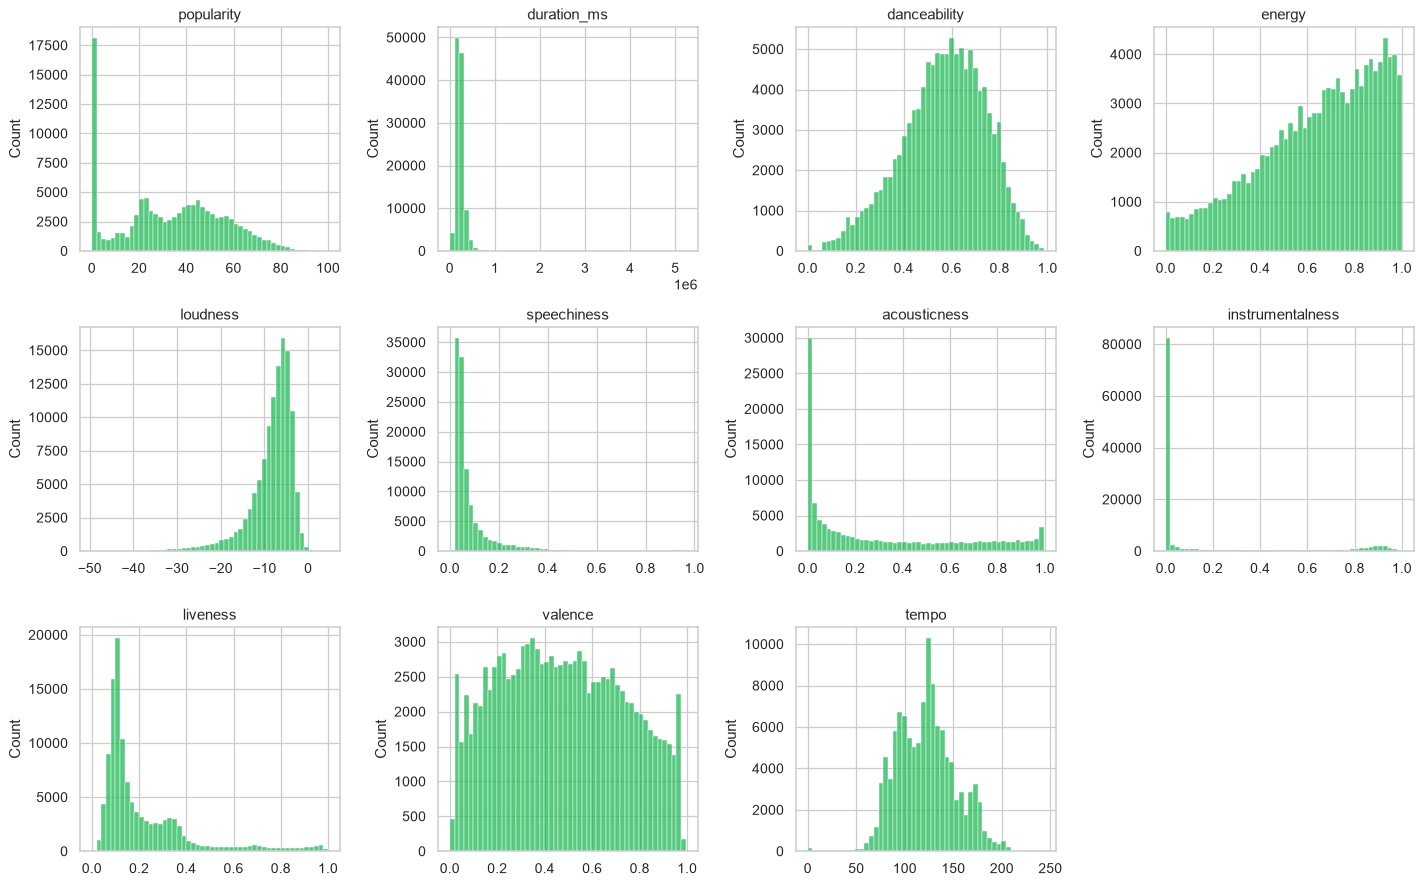

In [12]:
fig, axes = plt.subplots(3, 4, figsize=(16, 10))
for ax, col in zip(axes.flat, num_cols):
    sns.histplot(df[col], bins=50, ax=ax, color="#1DB954")
    ax.set_title(col)
    ax.set_xlabel("")
axes.flat[-1].set_visible(False)
plt.tight_layout()
plt.show()

**Observaciones:**

- `danceability`, `valence` y `tempo` tienen distribuciones aproximadamente simétricas.
- `energy` y `loudness` están sesgadas hacia valores altos (la mayoría de las canciones son enérgicas y fuertes).
- `speechiness`, `instrumentalness`, `liveness` y `acousticness` están muy sesgadas a la derecha: la mayoría de las canciones tienen valores cercanos a 0.
- `duration_ms` tiene una cola larga (canciones de hasta 87 minutos).

### 4.3 Outliers

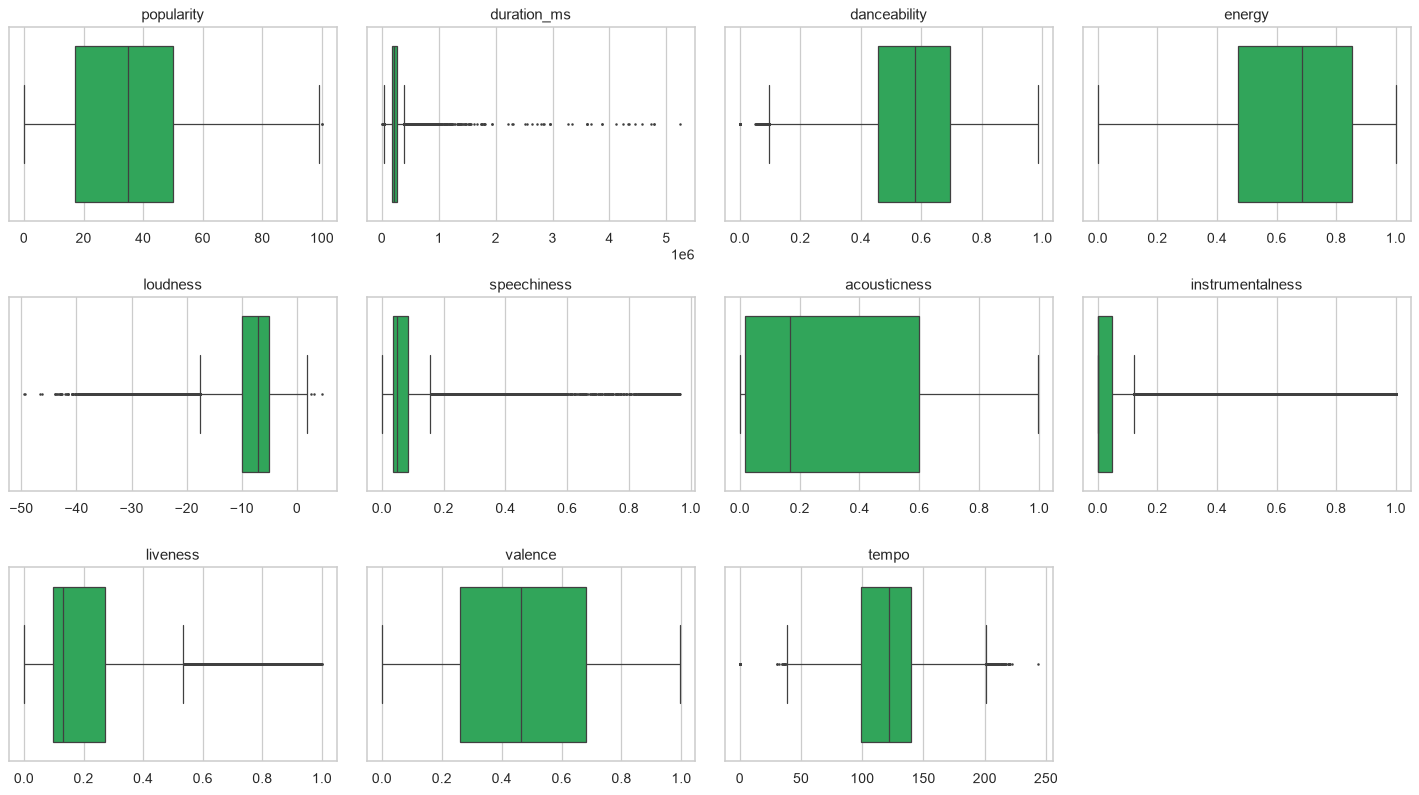

In [13]:
fig, axes = plt.subplots(3, 4, figsize=(16, 9))
for ax, col in zip(axes.flat, num_cols):
    sns.boxplot(x=df[col], ax=ax, color="#1DB954", fliersize=1)
    ax.set_title(col)
    ax.set_xlabel("")
axes.flat[-1].set_visible(False)
plt.tight_layout()
plt.show()

In [14]:
def outliers_iqr(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum()

out = df[num_cols].apply(outliers_iqr).rename("outliers").to_frame()
out["%"] = (out["outliers"] / len(df) * 100).round(2)
out.sort_values("outliers", ascending=False)

,outliers,%
instrumentalness,25246,22.15
speechiness,13211,11.59
liveness,8642,7.58
loudness,6173,5.41
duration_ms,5617,4.93
danceability,620,0.54
tempo,617,0.54
popularity,2,0.00
energy,0,0.00
acousticness,0,0.00


Muchos "outliers" por IQR (`speechiness`, `instrumentalness`, `liveness`) no son errores: son consecuencia natural de distribuciones sesgadas (p.ej. podcasts o música instrumental). Los únicos claramente erróneos son `tempo = 0` y duraciones extremas.

## 5. Variables categóricas

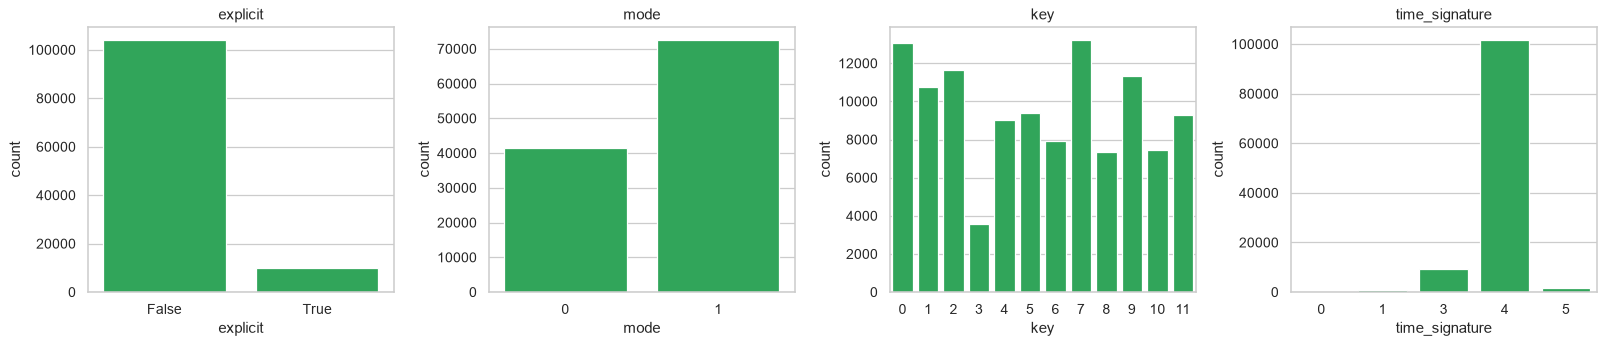

In [15]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, col in zip(axes, ["explicit", "mode", "key", "time_signature"]):
    sns.countplot(x=df[col], ax=ax, color="#1DB954")
    ax.set_title(col)
plt.tight_layout()
plt.show()

In [16]:
print(f"Explícitas: {df['explicit'].mean():.1%}")
print(f"Modo mayor: {df['mode'].mean():.1%}")
print(f"Géneros únicos: {df['track_genre'].nunique()}")
print(f"Artistas únicos: {df['artists'].nunique():,}")
df["track_genre"].value_counts().describe()

Explícitas: 8.6%
Modo mayor: 63.8%
Géneros únicos: 114
Artistas únicos: 31,437



count     114.0
mean     1000.0
std         0.0
min      1000.0
25%      1000.0
50%      1000.0
75%      1000.0
max      1000.0
Name: count, dtype: float64

- Solo el **8.6%** de las canciones son explícitas → clase desbalanceada.
- El compás 4/4 domina ampliamente.
- Los **114 géneros tienen exactamente 1.000 canciones cada uno**: el dataset fue construido balanceado por género.

## 6. Variable objetivo: `popularity`

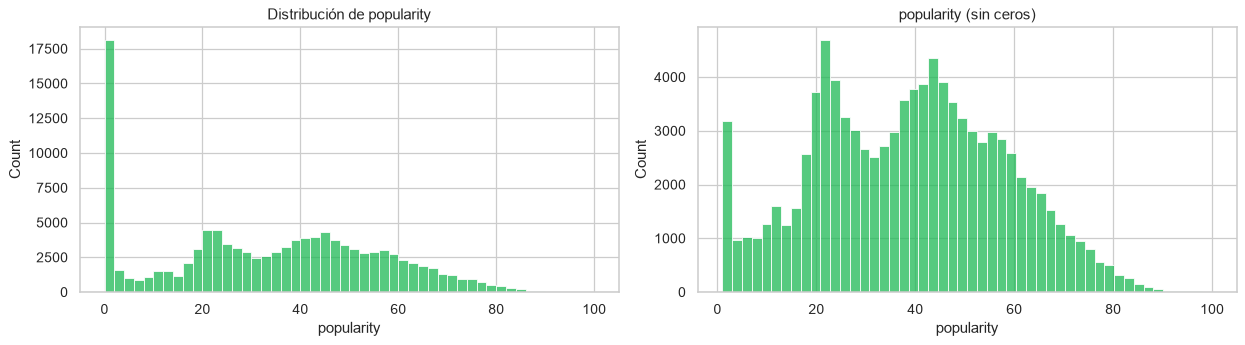

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(df["popularity"], bins=50, ax=axes[0], color="#1DB954")
axes[0].set_title("Distribución de popularity")
sns.histplot(df.loc[df["popularity"] > 0, "popularity"], bins=50, ax=axes[1], color="#1DB954")
axes[1].set_title("popularity (sin ceros)")
plt.tight_layout()
plt.show()

In [18]:
pop_track = df.drop_duplicates("track_id")
print(f"Canciones únicas: {len(pop_track):,}")
print(f"Con popularidad 0: {(pop_track['popularity'] == 0).mean():.1%}")
pop_track["popularity"].describe().round(2)

Canciones únicas: 89,741
Con popularidad 0: 10.5%



count    89741.00
mean        33.20
std         20.58
min          0.00
25%         19.00
50%         33.00
75%         49.00
max        100.00
Name: popularity, dtype: float64

Al quitar los ceros la distribución es aproximadamente normal, centrada en ~40. El pico en 0 probablemente corresponde a canciones sin datos de reproducción, no a canciones "impopulares".

## 7. Correlaciones

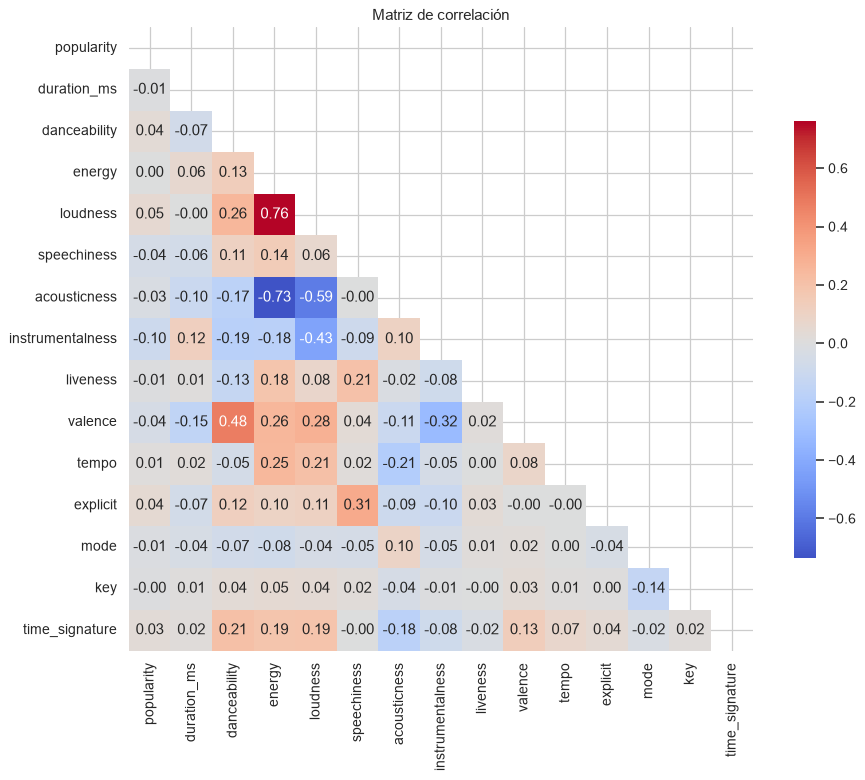

In [19]:
corr = df[num_cols + ["explicit", "mode", "key", "time_signature"]].astype(float).corr()

plt.figure(figsize=(12, 9))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True, cbar_kws={"shrink": 0.7})
plt.title("Matriz de correlación")
plt.show()

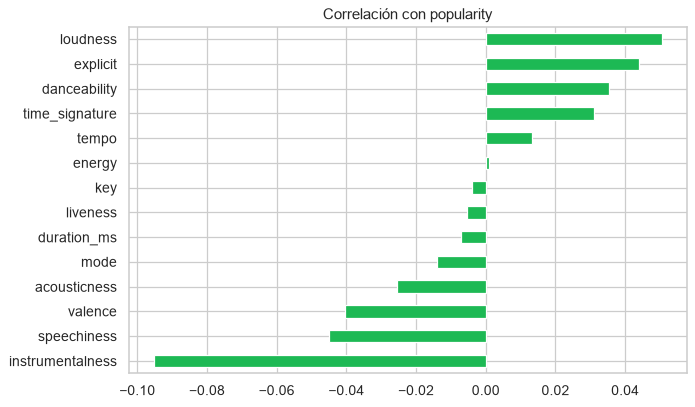

In [20]:
corr["popularity"].drop("popularity").sort_values().plot.barh(figsize=(8, 5), color="#1DB954")
plt.title("Correlación con popularity")
plt.show()

**Observaciones:**

- Correlaciones fuertes entre features: `energy`–`loudness` (+0.76) y `energy`–`acousticness` (−0.73). Hay multicolinealidad; para modelos lineales conviene considerarlo.
- `danceability`–`valence` (+0.48): las canciones bailables tienden a ser más alegres.
- **Ninguna característica de audio tiene correlación lineal relevante con `popularity`** (todas |r| < 0.1). La popularidad no se explica linealmente por el sonido.

## 8. Popularidad por género

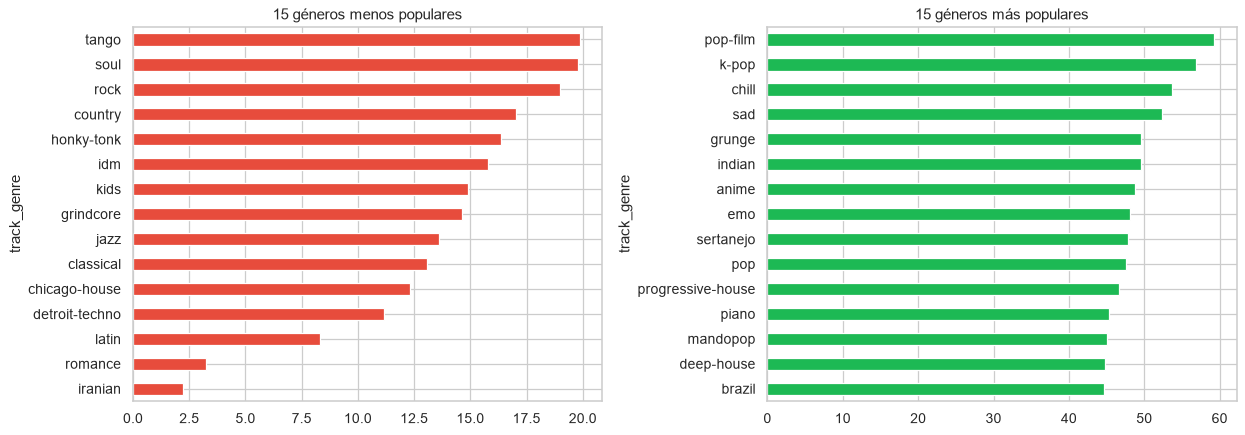

In [21]:
pop_gen = df.groupby("track_genre")["popularity"].mean().sort_values()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
pop_gen.head(15).plot.barh(ax=axes[0], color="#E74C3C")
axes[0].set_title("15 géneros menos populares")
pop_gen.tail(15).plot.barh(ax=axes[1], color="#1DB954")
axes[1].set_title("15 géneros más populares")
plt.tight_layout()
plt.show()

El género sí marca una gran diferencia: desde ~2 de popularidad media (`iranian`) hasta ~59 (`pop-film`). **`track_genre` es probablemente la variable más informativa para predecir popularidad.**

## 9. Relaciones entre variables

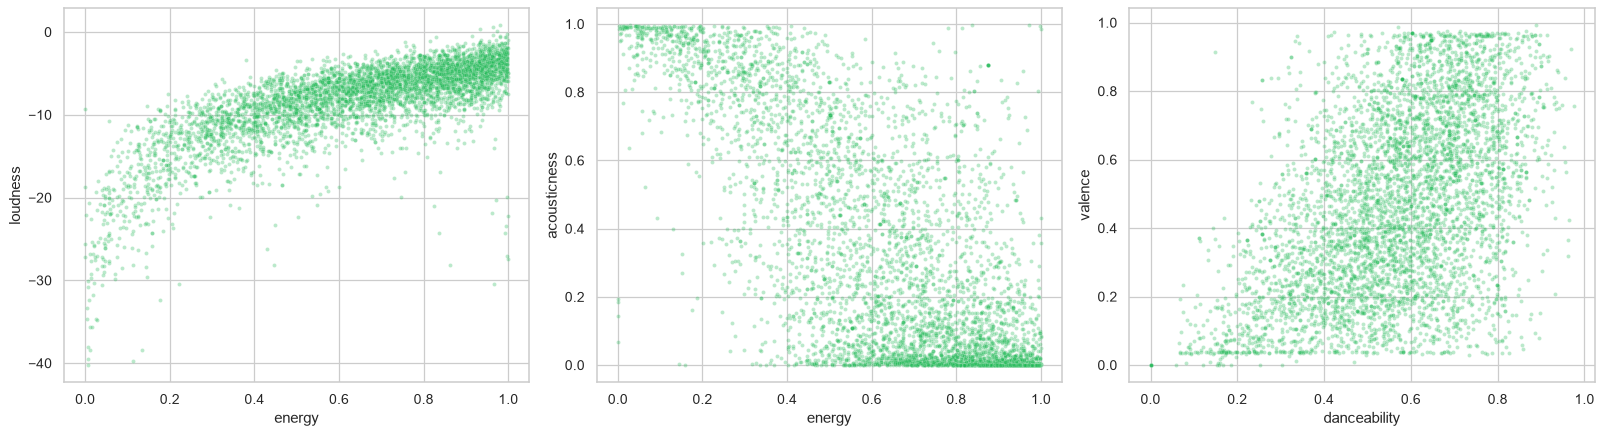

In [22]:
muestra = df.sample(5000, random_state=42)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.scatterplot(data=muestra, x="energy", y="loudness", alpha=0.3, s=10, ax=axes[0], color="#1DB954")
sns.scatterplot(data=muestra, x="energy", y="acousticness", alpha=0.3, s=10, ax=axes[1], color="#1DB954")
sns.scatterplot(data=muestra, x="danceability", y="valence", alpha=0.3, s=10, ax=axes[2], color="#1DB954")
plt.tight_layout()
plt.show()

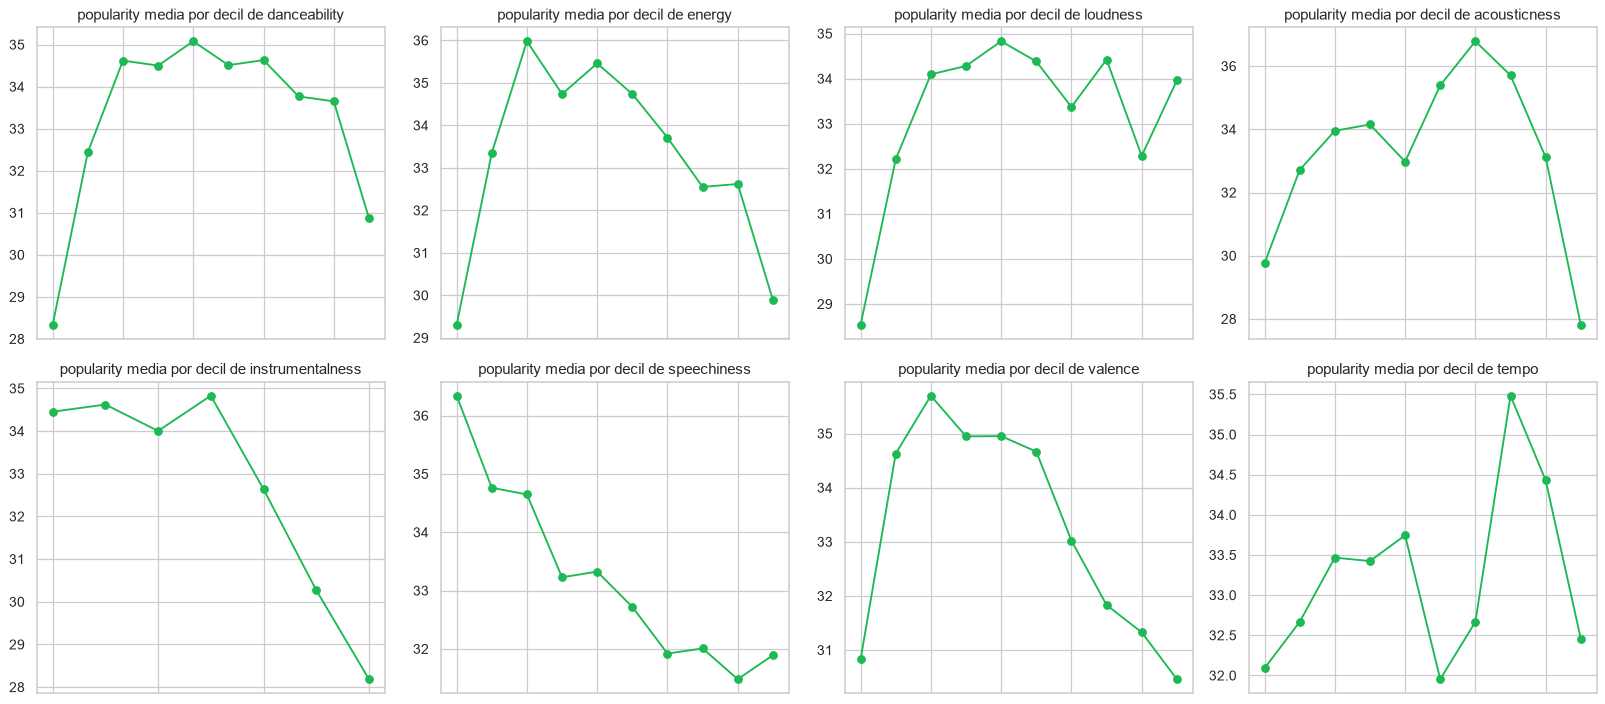

In [23]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
feats = ["danceability", "energy", "loudness", "acousticness",
         "instrumentalness", "speechiness", "valence", "tempo"]
for ax, col in zip(axes.flat, feats):
    bins = pd.qcut(df[col], 10, duplicates="drop")
    df.groupby(bins, observed=True)["popularity"].mean().plot(ax=ax, marker="o", color="#1DB954")
    ax.set_title(f"popularity media por decil de {col}")
    ax.set_xlabel("")
    ax.set_xticklabels([])
plt.tight_layout()
plt.show()

Al agrupar por deciles se ven algunas relaciones **no lineales** débiles (p.ej. las canciones muy instrumentales son menos populares). Modelos basados en árboles pueden capturarlas mejor que una regresión lineal.

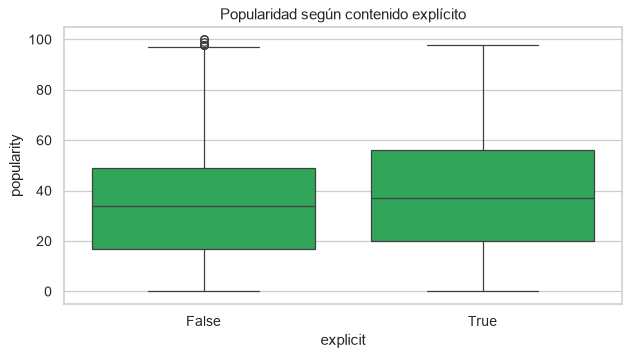


explicit
False    32.94
True     36.45
Name: popularity, dtype: float64

In [24]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.boxplot(data=df, x="explicit", y="popularity", ax=ax, color="#1DB954")
ax.set_title("Popularidad según contenido explícito")
plt.show()
df.groupby("explicit")["popularity"].mean().round(2)

## 10. Conclusiones del EDA

**Calidad de datos**
1. Eliminar `Unnamed: 0` (índice) y la única fila con nulos.
2. ~24 mil `track_id` repetidos: la misma canción en varios géneros. Deduplicar por `track_id` según el objetivo del modelo.
3. Tratar `tempo = 0` y `time_signature = 0` como errores (eliminar o imputar).
4. 14% de `popularity = 0`: evaluar si se excluyen o se tratan aparte.

**Hallazgos**
5. El dataset está balanceado: 1.000 canciones por cada uno de los 114 géneros.
6. Multicolinealidad entre `energy`, `loudness` y `acousticness`.
7. Las características de audio casi no tienen correlación lineal con `popularity`; el **género** sí es muy discriminante.
8. Las relaciones son no lineales → modelos de árboles (Random Forest, Gradient Boosting) son buenos candidatos.

**Próximos pasos**
- Crear el pipeline `data_processing` en Kedro con la limpieza descrita.
- Definir el target (regresión de `popularity` / clasificación de `track_genre` o de popularidad alta/baja) y el pipeline de modelado.